# Visualize framework atoms in clever ways
In this example, we learn how to visuaze the framework atoms, bonds and the aromatic rings using mofography and plotly in fully customizable ways. Having precise control let's you show exactly what you want in your illustrations, and even make some cool pictures for your Graphical Abstract if need be. Please refer to excellent Plotly documentationfor more information, all the plotting in mofography is done using Plotly. Mofography API documentation contains more information about plotting options. Also, some lines in this tutorial are commented out, try uncommenting them and running the cell for some alternate styles. 



## Tips and tricks #1:
The API docs for any of the functions may be accessed by `help(mgr.function_name)` or `mgr.function_name?` in a notebook cell.

## Tips and tricks #2:
Currently, the images are rendered using 'png' as the renderer, change it in the cell below to 'notebook_connected' or 'browser' for interactive views.

## Imports

In [1]:
#* make some imports
from ase.io import read
from ase.data.colors import cpk_colors, jmol_colors 

import plotly.graph_objects as go
import sys,os, inspect

#* add mofography to path (put your path here)
path_to_mgr = os.path.abspath('c:/Users/Arun Gopalan/OneDrive - The University of Manchester/my_cloned_repos/mofography')
sys.path.append(path_to_mgr)
import mofography as mgr 


# * change here if you want to plot elsewhere
# * 'browser' for example.

import plotly.io as pio 
pio.renderers.default='png'


## Read the cif file
As usual we read in the framework configuration use ASE, although we are using a CIF file in this example, any format supported by ASE should work.

- We then update the ase atoms object covalent bonds

As usual, we compute and update the 'covalent_bonds' to the ASE atoms objects for plotting purposes.

In [2]:
# * read file (put your path here)
filename =os.path.join(path_to_mgr,'examples', 'TestCIFs','P1-IRMOF-1.cif')
# filename ='./TestCIFs/super_nu1000.cif'
# Importing the cif file into the program. 
# filename = './zif-4.cif'
# filename = './TestCIFs/COD_2100028.cif'
# filename = './nu1000_2.cif'
# filename ='./LTA96.cif'
filename = os.path.abspath(filename)
mat_atoms = read(filename) # read file
mat_updated = mgr.update_with_covalent_bonds(mat_atoms) # compute bonds, bonds are under mat_updated.info['covalent_bonds']


c:\Users\Public\anaconda3\envs\jl_env\lib\site-packages\ase\io\cif.py:401: UserWarning:

crystal system 'triclinic' is not interpreted for space group Spacegroup(1, setting=1). This may result in wrong setting!



## Quick and dirty
Visualize the framework atoms and bonds as a mesh, quick and dirty, yet quite efficient. The stylize option adds a default set of lighting options to make it look cool. Turn it and see what happens. To create your own set of lighting options, refer to the plotly documentation here: https://plotly.com/python/reference/mesh3d/#mesh3d-lighting 

c:\Users\Public\anaconda3\envs\jl_env\lib\site-packages\ase\atoms.py:967: VisibleDeprecationWarning:

Use get_global_number_of_atoms() instead



No node props provided, using default set: [position, scaled_position, element and atomic_number]
No edge properties provided. Use the default set: [bond_order, bond_type]
isomorphic aromatic cycles is None, trying to calculate


c:\Users\Arun Gopalan\OneDrive - The University of Manchester\my_cloned_repos\mofography\mofography\visualize.py:767: UserWarning:

Optimal rotation is not uniquely or poorly defined for the given sets of vectors.



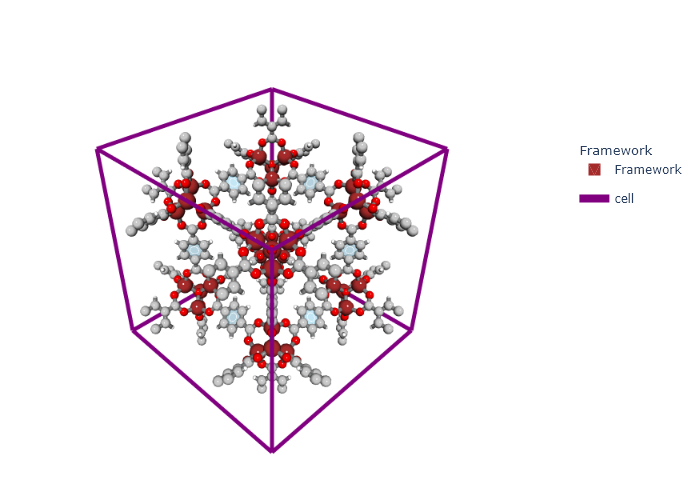

In [3]:
import plotly.graph_objects as go 
go.Figure([*mgr.plot_framework_as_mesh(mat_updated, stylize=True), mgr.plot_cell(mat_updated)], layout=mgr.white_layout).show()

## Customize atoms and bonds
You can create separate mesh objects for each of the atoms and bonds using mofography and customize things like transparency and color whichever way you like. Here is a cool demonstration of that. 

Make two lists of mesh objects (trimesh type), first list for atoms (spheres) and the second one for bonds (cylinders).


In [4]:
spheres = mgr.spheres_for_atoms(mat_updated, theta_resolution=30, phi_resolution=30)
cylinders = mgr.cylinders_for_bonds(mat_updated.info['covalent_bonds'],mat_updated, radius=0.15)

## Visualize everything 

Finally, plot all the meshes and the unit cell. Note that we are using the generic plot_mesh routine instead of the  plot_framework_as_mesh routine for more control and customizability. Note that in this we example, we are using a separate trace for the aromatic rings by calling the `plot_aromatics_rings` function to create a mesh 3D trace for the same. Please refer to the API docs for finer control on any of these functions options.

No node props provided, using default set: [position, scaled_position, element and atomic_number]
No edge properties provided. Use the default set: [bond_order, bond_type]
isomorphic aromatic cycles is None, trying to calculate


c:\Users\Arun Gopalan\OneDrive - The University of Manchester\my_cloned_repos\mofography\mofography\visualize.py:767: UserWarning:

Optimal rotation is not uniquely or poorly defined for the given sets of vectors.



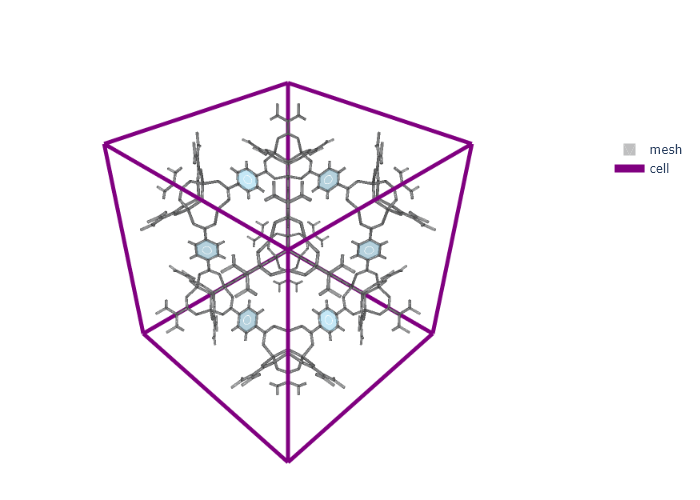

In [5]:

#* For finer control in plotting

#* Plot only the cyliders and aromatic rings
go.Figure([mgr.plot_mesh(cylinders, stylize=True, opacity=0.5), *mgr.plot_aromatic_rings(mat_updated), mgr.plot_cell(mat_updated)], layout=mgr.white_layout)

#* Plot the atoms, bonds and aromatic rings with full control
# go.Figure([mgr.plot_mesh(cylinders,stylize=False, opacity=1, name='bonds'), mgr.plot_mesh(spheres, opacity=0.5, stylize=True, name='atoms'),*mgr.plot_aromatic_rings(mat_updated)], layout=mgr.dark_layout)

